# C2 — Exploratory Data Analysis and Usefulness Target Selection

**Component 2:** Helpfulness-Guided Review Evidence Selection with Minority Preservation

This notebook performs the initial EDA for the PP1 development pilot prepared in `01_dataset_inspection.ipynb`.

## Main Goals

1. Check data quality and clean the smartphone pilot.
2. Analyse helpful-vote behaviour and sparsity.
3. Inspect ratings, verified purchases, timestamps and review length.
4. Check whether review age is related to helpful votes.
5. Compare candidate usefulness-target formulations:
   - raw helpful votes,
   - log-transformed helpful votes,
   - product-relative helpfulness,
   - age-adjusted helpfulness.
6. Prepare a chronological development split for the next modelling notebook.
7. Save reproducible EDA tables, figures and a cleaned pilot dataset.

> **Important:** This is preliminary PP1 development analysis. The pilot is not the final research evaluation dataset.


In [1]:
from pathlib import Path
import json
import math
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, spearmanr

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("EDA environment ready")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


EDA environment ready
Pandas: 3.0.6
NumPy: 2.5.3


## 1. Resolve Project Paths and Load the Pilot Dataset


In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate

    raise FileNotFoundError(
        "Could not locate the Component 2 project root."
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())

PILOT_PATH = (
    PROJECT_ROOT
    / "data"
    / "pilot"
    / "smartphone_pilot_raw.parquet"
)

CLEANED_PILOT_PATH = (
    PROJECT_ROOT
    / "data"
    / "pilot"
    / "smartphone_pilot_cleaned.parquet"
)

RESULTS_DIR = PROJECT_ROOT / "results" / "eda"
FIGURES_DIR = RESULTS_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Pilot dataset:", PILOT_PATH)
print("Results directory:", RESULTS_DIR)

if not PILOT_PATH.exists():
    raise FileNotFoundError(
        f"Pilot dataset not found at: {PILOT_PATH}"
    )


Project root: D:\Research\Repository\J26-DS-349\component_2
Pilot dataset: D:\Research\Repository\J26-DS-349\component_2\data\pilot\smartphone_pilot_raw.parquet
Results directory: D:\Research\Repository\J26-DS-349\component_2\results\eda


In [3]:
raw_df = pd.read_parquet(PILOT_PATH)

print("Raw pilot shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist())

display(raw_df.head())


Raw pilot shape: (899, 8)

Columns:
['rating', 'title', 'text', 'asin', 'parent_asin', 'timestamp', 'helpful_vote', 'verified_purchase']


,rating,title,text,asin,parent_asin,timestamp,helpful_vote,verified_purchase
0,5.0,Best phone yet,I love this phone it has everything and it does everything. And the camera,B08P54F6HB,B0B8PDLMMS,1631145062923,1,True
1,5.0,Value,Stays charged,B08B8Y5R4Y,B09HFW8GRB,1622928308584,0,True
2,5.0,Very nice phone,"The renewed phone arrived in perfect condition; no blemishes, no scratches, not even a fingerprint. After activating...",B082T4F34B,B09JJCXC2M,1632057913275,0,True
3,4.0,"Clean, unlocked and as described.","Love the Size, physical and memory. Not using the recognition features yet. It's my spouses phone and she wants to k...",B07P6SWG7T,B09JJCXC2M,1589921145585,0,True
4,2.0,Samsung Always Finds a Way to Ruin a Good Phone!,"Samsung seems to have a corporate mission statement and philosophy: if it works, update it and make sure it doesn't!...",B09BFVK7YP,B09PPWVQSB,1650318581193,0,True


## 2. Initial Data-Quality Audit


In [4]:
required_columns = [
    "rating",
    "title",
    "text",
    "asin",
    "parent_asin",
    "timestamp",
    "helpful_vote",
    "verified_purchase",
]

missing_columns = [
    col
    for col in required_columns
    if col not in raw_df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

audit = {
    "raw_rows": len(raw_df),
    "missing_text": int(raw_df["text"].isna().sum()),
    "empty_text": int(
        raw_df["text"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    ),
    "duplicate_product_text": int(
        raw_df.duplicated(
            subset=["parent_asin", "text"]
        ).sum()
    ),
    "missing_rating": int(
        raw_df["rating"].isna().sum()
    ),
    "missing_helpful_vote": int(
        raw_df["helpful_vote"].isna().sum()
    ),
    "missing_timestamp": int(
        raw_df["timestamp"].isna().sum()
    ),
    "missing_verified_purchase": int(
        raw_df["verified_purchase"].isna().sum()
    ),
}

audit_df = pd.DataFrame(
    {
        "metric": list(audit.keys()),
        "value": list(audit.values()),
    }
)

display(audit_df)


,metric,value
0,raw_rows,899
1,missing_text,0
2,empty_text,0
3,duplicate_product_text,3
4,missing_rating,0
5,missing_helpful_vote,0
6,missing_timestamp,0
7,missing_verified_purchase,0


In [5]:
df = raw_df.copy()

df["text"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["title"] = (
    df["title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce",
)

df["helpful_vote"] = pd.to_numeric(
    df["helpful_vote"],
    errors="coerce",
)

df["timestamp"] = pd.to_numeric(
    df["timestamp"],
    errors="coerce",
)

before = len(df)

df = df[df["text"].ne("")].copy()

df = df[
    df["rating"].between(
        1,
        5,
        inclusive="both",
    )
].copy()

df = df[
    df["helpful_vote"].fillna(-1) >= 0
].copy()

df = df[
    df["timestamp"].notna()
].copy()

df = df.drop_duplicates(
    subset=["parent_asin", "text"],
    keep="first",
).copy()

df["review_date"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True,
)

df = df[
    df["review_date"].notna()
].copy()

print("Rows before cleaning:", before)
print("Rows after cleaning:", len(df))
print("Rows removed:", before - len(df))


Rows before cleaning: 899
Rows after cleaning: 896
Rows removed: 3


### Create Stable Review Identifiers

A deterministic `review_id` is created for each cleaned review so that the same review can be traced consistently through usefulness scoring, C1 joins, chronological splits, and later evidence selection.


In [6]:
def make_review_id(row):
    key = "||".join(
        [
            str(row.get("parent_asin", "")),
            str(row.get("asin", "")),
            str(row.get("timestamp", "")),
            str(row.get("title", "")),
            str(row.get("text", "")),
        ]
    )

    return hashlib.sha256(
        key.encode("utf-8")
    ).hexdigest()[:16]


df["review_id"] = df.apply(
    make_review_id,
    axis=1,
)

duplicate_review_ids = int(
    df["review_id"]
    .duplicated()
    .sum()
)

print("Rows:", len(df))
print(
    "Unique review IDs:",
    df["review_id"].nunique(),
)
print(
    "Duplicate review IDs:",
    duplicate_review_ids,
)

if duplicate_review_ids != 0:
    raise ValueError(
        "Stable review_id generation produced duplicates."
    )

display(
    df[
        [
            "review_id",
            "parent_asin",
            "asin",
            "timestamp",
            "helpful_vote",
        ]
    ].head()
)


Rows: 896
Unique review IDs: 896
Duplicate review IDs: 0


,review_id,parent_asin,asin,timestamp,helpful_vote
0,26c3cd248dc3d01d,B0B8PDLMMS,B08P54F6HB,1631145062923,1
1,cd97cd121c0fc4b7,B09HFW8GRB,B08B8Y5R4Y,1622928308584,0
2,293639dc0ec21eae,B09JJCXC2M,B082T4F34B,1632057913275,0
3,5a4857744877f56c,B09JJCXC2M,B07P6SWG7T,1589921145585,0
4,ca2d0d6e3ea776f8,B09PPWVQSB,B09BFVK7YP,1650318581193,0


## 3. Create Basic Review Features


In [7]:
df["review_length_words"] = (
    df["text"]
    .str.split()
    .str.len()
    .astype(int)
)

df["review_length_chars"] = (
    df["text"]
    .str.len()
    .astype(int)
)

df["verified_purchase"] = (
    df["verified_purchase"]
    .fillna(False)
    .astype(bool)
)

print("Cleaned shape:", df.shape)

display(
    df[
        [
            "parent_asin",
            "rating",
            "helpful_vote",
            "verified_purchase",
            "review_date",
            "review_length_words",
            "text",
        ]
    ].head()
)


Cleaned shape: (896, 12)


,parent_asin,rating,helpful_vote,verified_purchase,review_date,review_length_words,text
0,B0B8PDLMMS,5.0,1,True,2021-09-08 23:51:02.923000+00:00,14,I love this phone it has everything and it does everything. And the camera
1,B09HFW8GRB,5.0,0,True,2021-06-05 21:25:08.584000+00:00,2,Stays charged
2,B09JJCXC2M,5.0,0,True,2021-09-19 13:25:13.275000+00:00,81,"The renewed phone arrived in perfect condition; no blemishes, no scratches, not even a fingerprint. After activating..."
3,B09JJCXC2M,4.0,0,True,2020-05-19 20:45:45.585000+00:00,59,"Love the Size, physical and memory. Not using the recognition features yet. It's my spouses phone and she wants to k..."
4,B09PPWVQSB,2.0,0,True,2022-04-18 21:49:41.193000+00:00,36,"Samsung seems to have a corporate mission statement and philosophy: if it works, update it and make sure it doesn't!..."


## 4. Helpful-Vote Distribution


In [8]:
helpful_summary = (
    df["helpful_vote"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

zero_helpful_count = int(
    (df["helpful_vote"] == 0).sum()
)

zero_helpful_pct = float(
    (df["helpful_vote"] == 0).mean()
    * 100
)

positive_helpful_count = int(
    (df["helpful_vote"] > 0).sum()
)

raw_skew = float(
    skew(
        df["helpful_vote"],
        bias=False,
    )
)

display(
    helpful_summary.to_frame(
        "helpful_vote"
    )
)

print(
    "Zero helpful-vote reviews:",
    zero_helpful_count,
)

print(
    f"Zero helpful-vote percentage: "
    f"{zero_helpful_pct:.2f}%"
)

print(
    "Positive helpful-vote reviews:",
    positive_helpful_count,
)

print(
    f"Raw helpful-vote skewness: "
    f"{raw_skew:.3f}"
)


,helpful_vote
count,896.000000
mean,2.107143
std,7.720662
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
90%,5.000000
95%,9.000000
99%,38.050000


Zero helpful-vote reviews: 550
Zero helpful-vote percentage: 61.38%
Positive helpful-vote reviews: 346
Raw helpful-vote skewness: 8.392


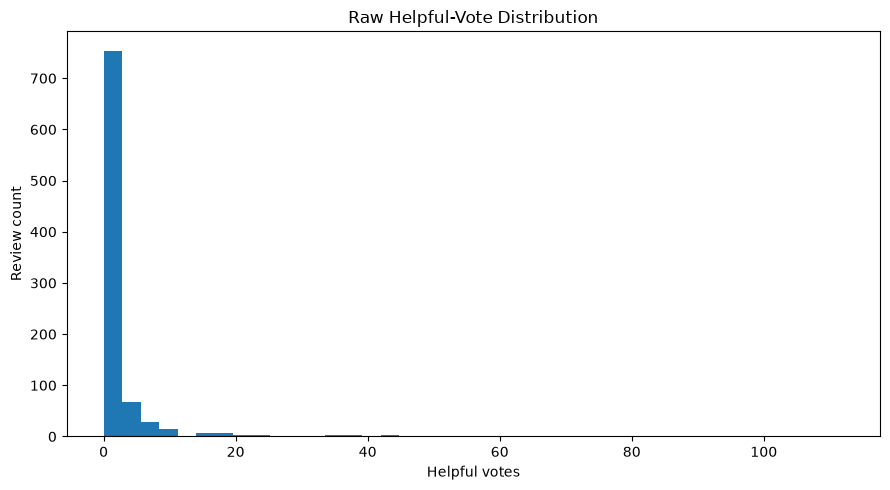

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\helpful_votes_raw_histogram.png


In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    df["helpful_vote"],
    bins=40,
)

ax.set_title(
    "Raw Helpful-Vote Distribution"
)

ax.set_xlabel("Helpful votes")
ax.set_ylabel("Review count")

plt.tight_layout()

raw_hist_path = (
    FIGURES_DIR
    / "helpful_votes_raw_histogram.png"
)

plt.savefig(
    raw_hist_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Saved:", raw_hist_path)


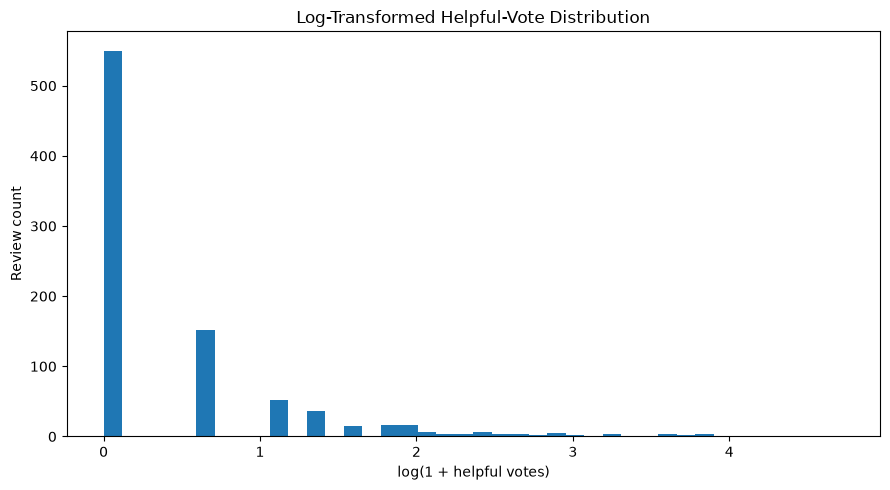

Log-helpful skewness: 1.971
Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\helpful_votes_log_histogram.png


In [10]:
df["log_helpful"] = np.log1p(
    df["helpful_vote"]
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    df["log_helpful"],
    bins=40,
)

ax.set_title(
    "Log-Transformed Helpful-Vote Distribution"
)

ax.set_xlabel(
    "log(1 + helpful votes)"
)

ax.set_ylabel("Review count")

plt.tight_layout()

log_hist_path = (
    FIGURES_DIR
    / "helpful_votes_log_histogram.png"
)

plt.savefig(
    log_hist_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

log_skew = float(
    skew(
        df["log_helpful"],
        bias=False,
    )
)

print(
    f"Log-helpful skewness: "
    f"{log_skew:.3f}"
)

print("Saved:", log_hist_path)


In [11]:
display(
    df[
        [
            "parent_asin",
            "helpful_vote",
            "rating",
            "review_date",
            "review_length_words",
            "text",
        ]
    ]
    .sort_values(
        "helpful_vote",
        ascending=False,
    )
    .head(15)
)


,parent_asin,helpful_vote,rating,review_date,review_length_words,text
738,B08PP9FM9N,112,5.0,2021-05-06 02:14:49.217000+00:00,535,"Like some of the other reviewers, I had concern about the condition of a 'renewed' phone. As it turned out, it arriv..."
498,B09PPWVQSB,89,5.0,2022-07-26 01:09:35.700000+00:00,657,"I got my S9 after my S4 crapped out after 5 years (screen went off, wasn't even cracked). My S4 & S9 served me very..."
509,B0BMWTL2S6,82,5.0,2022-02-27 05:56:11.472000+00:00,17,There are no two ways about it. Samsung has made the superior device. Love everything about it.
171,B07GYY6VTD,74,3.0,2018-08-03 10:34:44.430000+00:00,621,What a disappointment! My first Motorola phone in years have let me down.<br /><br />Let's talk about the pros:<br /...
187,B07GYY6VTD,48,1.0,2018-08-08 03:16:32.393000+00:00,277,"I have had this phone for two weeks -<br />I have to say, I am not thrilled with this phone. It seems as though it'..."
862,B0B8PDLMMS,44,1.0,2021-02-15 23:19:01.344000+00:00,11,Bran new phone came scratched right out of the box. Unbelievable.
842,B0B8PDLMMS,43,5.0,2021-02-05 20:33:25.776000+00:00,1772,"For the record, I was very unsure of this upgrade. I have been a Note user for the last 10 years. I have never owned..."
14,B09PPWVQSB,40,4.0,2020-10-29 18:47:59.268000+00:00,570,"Now that the price on this phone has gone down to $600, it is a very good deal for the price.<br /><br />The Snapdra..."
724,B0B8PDLMMS,39,5.0,2021-03-10 19:17:21.342000+00:00,189,This is by far the best Samsung Galaxy Flagship phone. I have changed my phone from iPhone 11 to S21 and this phone...
893,B08PP9FM9N,38,5.0,2022-02-17 06:33:59.540000+00:00,342,"Ignore the smudges on the second photo, those are not scratches.<br /><br />My boyfriend wanted a newer phone, we we..."


## 5. Rating and Verified-Purchase Distributions


In [12]:
rating_distribution = (
    df["rating"]
    .value_counts()
    .sort_index()
    .rename("review_count")
    .to_frame()
)

verified_distribution = (
    df["verified_purchase"]
    .value_counts(
        dropna=False
    )
    .rename("review_count")
    .to_frame()
)

print("Rating distribution:")
display(rating_distribution)

print(
    "Verified-purchase distribution:"
)
display(verified_distribution)

verified_pct = float(
    df["verified_purchase"]
    .mean()
    * 100
)

print(
    f"Verified-purchase percentage: "
    f"{verified_pct:.2f}%"
)


Rating distribution:


,review_count
rating,
1.0,125
2.0,59
3.0,62
4.0,117
5.0,533


Verified-purchase distribution:


,review_count
verified_purchase,
True,835
False,61


Verified-purchase percentage: 93.19%


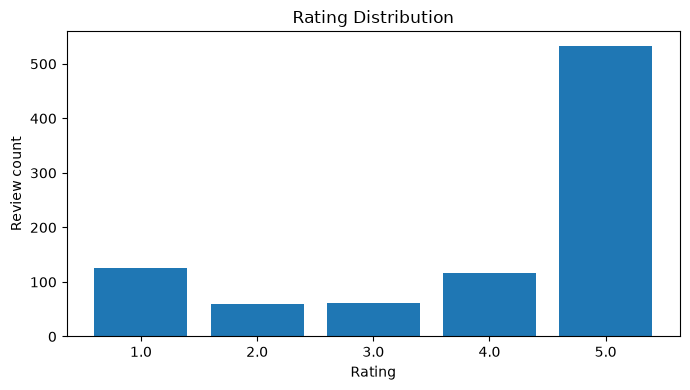

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\rating_distribution.png


In [13]:
fig, ax = plt.subplots(figsize=(7, 4))

rating_counts = (
    df["rating"]
    .value_counts()
    .sort_index()
)

ax.bar(
    rating_counts.index.astype(str),
    rating_counts.values,
)

ax.set_title("Rating Distribution")
ax.set_xlabel("Rating")
ax.set_ylabel("Review count")

plt.tight_layout()

rating_plot_path = (
    FIGURES_DIR
    / "rating_distribution.png"
)

plt.savefig(
    rating_plot_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Saved:", rating_plot_path)


## 6. Timestamp Range and Approximate Review Age


In [14]:
earliest_review = (
    df["review_date"].min()
)

latest_review = (
    df["review_date"].max()
)

print(
    "Earliest review:",
    earliest_review,
)

print(
    "Latest review:",
    latest_review,
)

print(
    "Time span:",
    latest_review - earliest_review,
)

reference_date = (
    latest_review
    + pd.Timedelta(days=1)
)

df["age_days"] = (
    (
        reference_date
        - df["review_date"]
    )
    .dt.total_seconds()
    .div(86400)
    .clip(lower=1)
)

display(
    df["age_days"]
    .describe()
    .to_frame("age_days")
)


Earliest review: 2018-07-06 05:05:59.337000+00:00
Latest review: 2023-03-19 04:55:16.370000+00:00
Time span: 1716 days 23:49:17.033000


,age_days
count,896.000000
mean,657.638665
std,472.409535
min,1.000000
25%,236.034083
50%,595.935128
75%,973.055173
max,1717.992558


In [15]:
age_helpful_corr = spearmanr(
    df["age_days"],
    df["helpful_vote"],
    nan_policy="omit",
)

print(
    "Spearman correlation between "
    "review age and helpful votes:"
)

print(
    f"rho = "
    f"{age_helpful_corr.statistic:.4f}"
)

print(
    f"p-value = "
    f"{age_helpful_corr.pvalue:.6g}"
)


Spearman correlation between review age and helpful votes:
rho = -0.0702
p-value = 0.0356298


## 7. Review-Length Analysis


In [16]:
length_summary = (
    df[
        [
            "review_length_words",
            "review_length_chars",
        ]
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)

display(length_summary)

length_helpful_corr = spearmanr(
    df["review_length_words"],
    df["helpful_vote"],
    nan_policy="omit",
)

print(
    "Spearman correlation between "
    "review length and helpful votes:"
)

print(
    f"rho = "
    f"{length_helpful_corr.statistic:.4f}"
)

print(
    f"p-value = "
    f"{length_helpful_corr.pvalue:.6g}"
)


,review_length_words,review_length_chars
count,896.000000,896.000000
mean,72.633929,391.572545
std,122.183377,663.480273
min,1.000000,4.000000
25%,16.000000,89.500000
50%,39.500000,210.500000
75%,83.250000,453.250000
90%,153.500000,838.500000
95%,224.750000,1231.750000
99%,543.400000,3093.250000


Spearman correlation between review length and helpful votes:
rho = 0.4314
p-value = 6.46855e-42


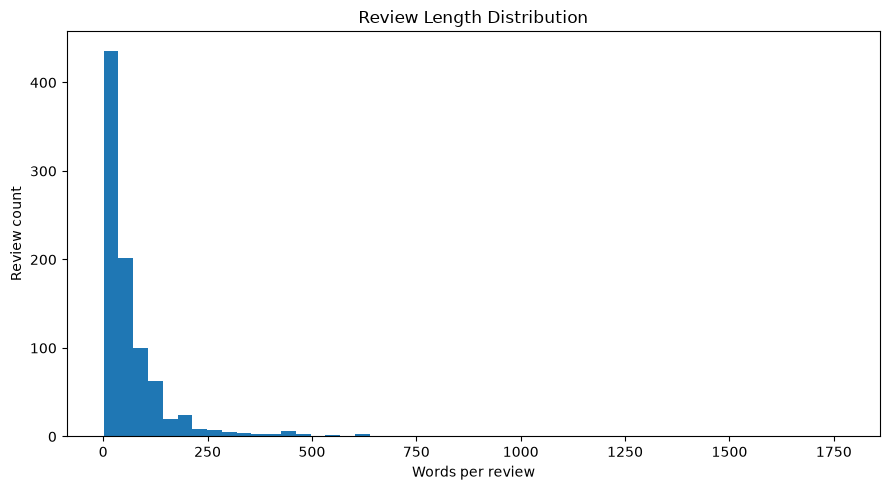

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\review_length_distribution.png


In [17]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    df["review_length_words"],
    bins=50,
)

ax.set_title(
    "Review Length Distribution"
)

ax.set_xlabel("Words per review")
ax.set_ylabel("Review count")

plt.tight_layout()

length_plot_path = (
    FIGURES_DIR
    / "review_length_distribution.png"
)

plt.savefig(
    length_plot_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Saved:", length_plot_path)


## 8. Product-Level EDA


In [18]:
product_summary = (
    df.groupby("parent_asin")
    .agg(
        review_count=(
            "text",
            "size",
        ),
        avg_rating=(
            "rating",
            "mean",
        ),
        mean_helpful_vote=(
            "helpful_vote",
            "mean",
        ),
        median_helpful_vote=(
            "helpful_vote",
            "median",
        ),
        max_helpful_vote=(
            "helpful_vote",
            "max",
        ),
        zero_helpful_pct=(
            "helpful_vote",
            lambda x:
                (x == 0)
                .mean()
                * 100,
        ),
        verified_purchase_pct=(
            "verified_purchase",
            lambda x:
                x.mean()
                * 100,
        ),
        avg_review_length_words=(
            "review_length_words",
            "mean",
        ),
        earliest_review=(
            "review_date",
            "min",
        ),
        latest_review=(
            "review_date",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        "review_count",
        ascending=False,
    )
)

display(product_summary)

product_summary_path = (
    RESULTS_DIR
    / "product_summary.csv"
)

product_summary.to_csv(
    product_summary_path,
    index=False,
)

print(
    "Saved:",
    product_summary_path,
)


,parent_asin,review_count,avg_rating,mean_helpful_vote,median_helpful_vote,max_helpful_vote,zero_helpful_pct,verified_purchase_pct,avg_review_length_words,earliest_review,latest_review
0,B07GYY6VTD,100,3.810000,1.900000,0.0,74,71.000000,84.000000,68.410000,2018-07-06 05:05:59.337000+00:00,2020-12-01 22:57:39.208000+00:00
3,B08XRDVWQ2,100,3.830000,1.030000,0.0,17,68.000000,96.000000,88.260000,2019-08-30 21:01:06.018000+00:00,2022-10-04 11:18:10.352000+00:00
9,B0BMWTL2S6,100,4.100000,3.500000,1.0,82,38.000000,91.000000,65.120000,2022-02-27 05:56:11.472000+00:00,2023-03-16 20:46:05.543000+00:00
5,B09JJCXC2M,100,4.230000,0.990000,0.0,26,70.000000,97.000000,61.790000,2019-08-13 14:20:34.574000+00:00,2023-03-01 02:49:21.830000+00:00
8,B0BL9TKSBL,100,3.900000,1.830000,0.0,24,53.000000,95.000000,68.180000,2021-02-23 21:44:29.064000+00:00,2023-03-13 12:06:08.417000+00:00
6,B09PPWVQSB,100,3.890000,2.860000,0.0,89,56.000000,88.000000,81.680000,2020-10-07 12:12:20.480000+00:00,2023-03-07 01:59:31.946000+00:00
1,B07SDQ483V,83,4.024096,0.710843,0.0,34,80.722892,97.590361,59.518072,2018-12-13 18:33:39.396000+00:00,2021-03-27 11:46:42.276000+00:00
4,B09HFW8GRB,77,3.974026,1.753247,0.0,28,59.740260,98.701299,55.051948,2020-08-08 00:47:40.580000+00:00,2023-03-11 22:08:19.491000+00:00
7,B0B8PDLMMS,75,3.893333,3.906667,0.0,44,50.666667,90.666667,126.320000,2021-02-05 20:33:25.776000+00:00,2022-10-21 08:22:56.467000+00:00
2,B08PP9FM9N,61,4.163934,3.114754,0.0,112,70.491803,96.721311,50.540984,2021-04-25 19:32:30.138000+00:00,2023-03-19 04:55:16.370000+00:00


Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\product_summary.csv


## 9. Candidate Usefulness Targets

Four candidate target formulations are compared:

- `raw_helpful`
- `log_helpful`
- `product_relative`
- `age_adjusted`

These are preliminary PP1 candidates, not automatically final research targets.


In [19]:
df["raw_helpful"] = (
    df["helpful_vote"]
    .astype(float)
)

df["log_helpful"] = (
    np.log1p(
        df["helpful_vote"]
    )
)

df["product_relative"] = (
    df.groupby(
        "parent_asin"
    )["log_helpful"]
    .rank(
        method="average",
        pct=True,
    )
)

effective_age_days = (
    df["age_days"]
    .clip(lower=30)
)

df["age_adjusted"] = (
    df["helpful_vote"]
    / effective_age_days
    * 365.25
)

target_columns = [
    "raw_helpful",
    "log_helpful",
    "product_relative",
    "age_adjusted",
]

display(
    df[target_columns].head()
)


,raw_helpful,log_helpful,product_relative,age_adjusted
0,1.0,0.693147,0.606667,0.655496
1,0.0,0.000000,0.305195,0.000000
2,0.0,0.000000,0.355000,0.000000
3,0.0,0.000000,0.355000,0.000000
4,0.0,0.000000,0.285000,0.000000


In [20]:
def safe_skew(series):
    clean = series.dropna()

    if (
        len(clean) < 3
        or clean.nunique() <= 1
    ):
        return np.nan

    return float(
        skew(
            clean,
            bias=False,
        )
    )


def target_diagnostics(
    data,
    target,
):
    s = data[target].dropna()

    return {
        "target": target,
        "count": int(len(s)),
        "unique_values": int(
            s.nunique()
        ),
        "zero_pct": float(
            (s == 0)
            .mean()
            * 100
        ),
        "mean": float(
            s.mean()
        ),
        "median": float(
            s.median()
        ),
        "std": float(
            s.std()
        ),
        "min": float(
            s.min()
        ),
        "max": float(
            s.max()
        ),
        "skewness": safe_skew(s),
    }


target_diagnostics_df = (
    pd.DataFrame(
        [
            target_diagnostics(
                df,
                target,
            )
            for target
            in target_columns
        ]
    )
)

display(
    target_diagnostics_df
)

target_diagnostics_path = (
    RESULTS_DIR
    / "target_diagnostics.csv"
)

target_diagnostics_df.to_csv(
    target_diagnostics_path,
    index=False,
)

print(
    "Saved:",
    target_diagnostics_path,
)


,target,count,unique_values,zero_pct,mean,median,std,min,max,skewness
0,raw_helpful,896,34,61.383929,2.107143,0.000000,7.720662,0.000,112.000000,8.392158
1,log_helpful,896,34,61.383929,0.517610,0.000000,0.832361,0.000,4.727388,1.970910
2,product_relative,896,70,0.000000,0.505580,0.360656,0.247916,0.195,1.000000,0.671174
3,age_adjusted,896,344,61.383929,2.668374,0.000000,11.567764,0.000,206.975000,10.524653


Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\target_diagnostics.csv


In [21]:
correlation_rows = []

for target in target_columns:

    corr = spearmanr(
        df["raw_helpful"],
        df[target],
        nan_policy="omit",
    )

    correlation_rows.append(
        {
            "target": target,
            "spearman_vs_raw_helpful":
                corr.statistic,
            "p_value":
                corr.pvalue,
        }
    )

target_rank_correlation_df = (
    pd.DataFrame(
        correlation_rows
    )
)

display(
    target_rank_correlation_df
)

rank_corr_path = (
    RESULTS_DIR
    / "target_rank_correlations.csv"
)

target_rank_correlation_df.to_csv(
    rank_corr_path,
    index=False,
)

print(
    "Saved:",
    rank_corr_path,
)


,target,spearman_vs_raw_helpful,p_value
0,raw_helpful,1.000000,0.000000e+00
1,log_helpful,1.000000,0.000000e+00
2,product_relative,0.864030,1.073693e-268
3,age_adjusted,0.978967,0.000000e+00


Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\target_rank_correlations.csv


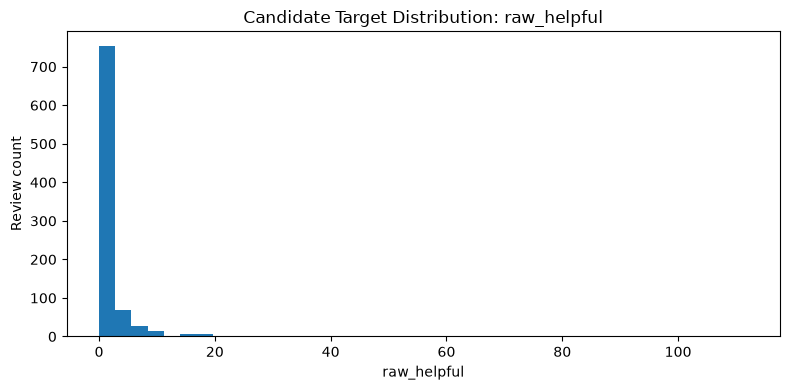

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\target_raw_helpful_histogram.png


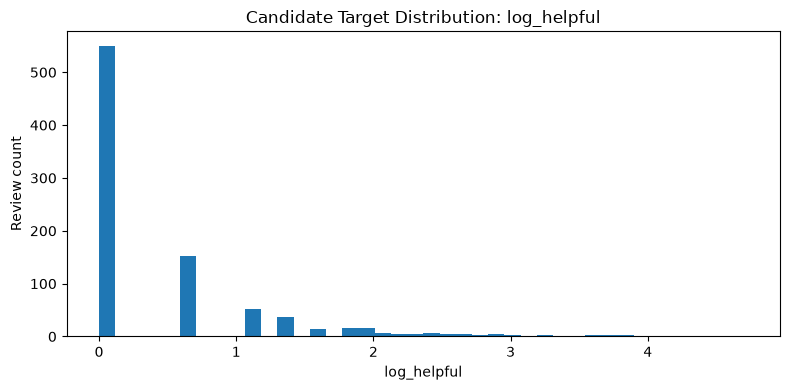

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\target_log_helpful_histogram.png


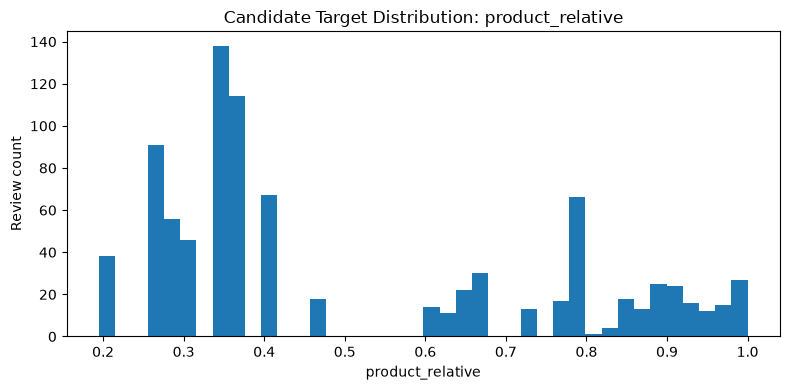

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\target_product_relative_histogram.png


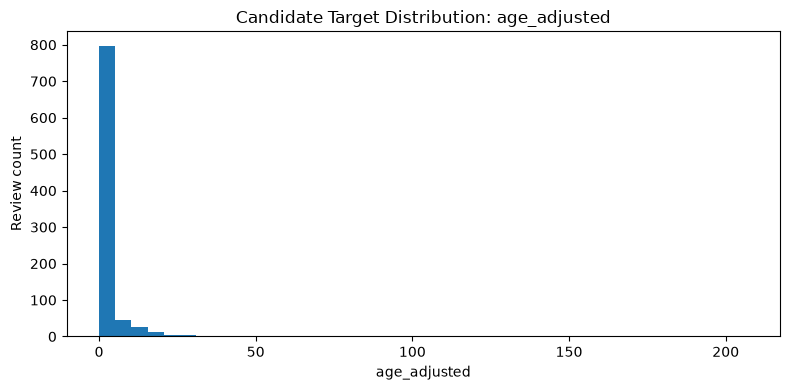

Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\figures\target_age_adjusted_histogram.png


In [22]:
for target in target_columns:

    fig, ax = plt.subplots(
        figsize=(8, 4)
    )

    ax.hist(
        df[target].dropna(),
        bins=40,
    )

    ax.set_title(
        f"Candidate Target Distribution: "
        f"{target}"
    )

    ax.set_xlabel(target)
    ax.set_ylabel("Review count")

    plt.tight_layout()

    path = (
        FIGURES_DIR
        / f"target_{target}_histogram.png"
    )

    plt.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", path)


## 10. Target-Selection Evidence Summary


In [23]:
raw_diag = (
    target_diagnostics_df
    .set_index("target")
    .loc["raw_helpful"]
)

log_diag = (
    target_diagnostics_df
    .set_index("target")
    .loc["log_helpful"]
)

print(
    "=== TARGET-SELECTION EVIDENCE ==="
)

print(
    f"Zero helpful-vote percentage: "
    f"{zero_helpful_pct:.2f}%"
)

print(
    f"Raw helpful skewness: "
    f"{raw_diag['skewness']:.3f}"
)

print(
    f"Log helpful skewness: "
    f"{log_diag['skewness']:.3f}"
)

print(
    "Age vs helpful-vote "
    "Spearman rho:",
    f"{age_helpful_corr.statistic:.4f}",
)

print(
    "Number of products:",
    df["parent_asin"].nunique(),
)

print("\nInterpretation prompts:")

print(
    "- If raw helpful votes are extremely "
    "skewed, log_helpful is a stronger "
    "regression candidate."
)

print(
    "- If vote scales differ strongly "
    "between products, product_relative "
    "is useful as a ranking-oriented "
    "comparison target."
)

print(
    "- If review age is meaningfully "
    "correlated with helpful votes, "
    "age bias should be considered."
)

print(
    "- A zero-heavy target may require "
    "ranking/classification-oriented "
    "baselines in addition to regression."
)


=== TARGET-SELECTION EVIDENCE ===
Zero helpful-vote percentage: 61.38%
Raw helpful skewness: 8.392
Log helpful skewness: 1.971
Age vs helpful-vote Spearman rho: -0.0702
Number of products: 10

Interpretation prompts:
- If raw helpful votes are extremely skewed, log_helpful is a stronger regression candidate.
- If vote scales differ strongly between products, product_relative is useful as a ranking-oriented comparison target.
- If review age is meaningfully correlated with helpful votes, age bias should be considered.
- A zero-heavy target may require ranking/classification-oriented baselines in addition to regression.


### Research Decision Record — Fill After Running

After inspecting the actual outputs, replace the placeholders below.

> **Selected preliminary usefulness target:** `<target name>`  
> **Reason:** `<evidence from EDA>`  
> **Alternative retained for sensitivity analysis:** `<target name>`  
> **Limitation:** `<important limitation>`

Do not commit this notebook with the placeholders unchanged.


## 11. Chronological Development Split

For this PP1 pilot:

- 70% earliest reviews → train
- next 15% → validation
- final 15% → test

The split is applied separately within each product.


In [24]:
def chronological_split_group(
    group,
):
    group = (
        group
        .sort_values(
            "review_date"
        )
        .copy()
    )

    n = len(group)

    train_end = max(
        1,
        int(
            math.floor(
                n * 0.70
            )
        ),
    )

    val_end = max(
        train_end + 1,
        int(
            math.floor(
                n * 0.85
            )
        ),
    )

    val_end = min(
        val_end,
        n,
    )

    split = np.array(
        ["test"] * n,
        dtype=object,
    )

    split[:train_end] = "train"

    split[
        train_end:val_end
    ] = "validation"

    if n == 1:
        split[:] = "train"

    elif n == 2:
        split[0] = "train"
        split[1] = "test"

    group["split"] = split

    return group


split_parts = []

for _, group in df.groupby(
    "parent_asin",
    sort=False,
):
    split_parts.append(
        chronological_split_group(
            group
        )
    )

split_df = pd.concat(
    split_parts,
    ignore_index=True,
)

print(
    "Overall split counts:"
)

display(
    split_df["split"]
    .value_counts()
    .to_frame(
        "review_count"
    )
)

print(
    "Per-product split counts:"
)

display(
    pd.crosstab(
        split_df["parent_asin"],
        split_df["split"],
    )
)


Overall split counts:


,review_count
split,
train,625
test,137
validation,134


Per-product split counts:


split,test,train,validation
parent_asin,,,
B07GYY6VTD,15,70,15
B07SDQ483V,13,58,12
B08PP9FM9N,10,42,9
B08XRDVWQ2,15,70,15
B09HFW8GRB,12,53,12
B09JJCXC2M,15,70,15
B09PPWVQSB,15,70,15
B0B8PDLMMS,12,52,11
B0BL9TKSBL,15,70,15


## 12. Save Cleaned Pilot and EDA Evidence


In [25]:
columns_to_save = [
    "review_id",
    "rating",
    "title",
    "text",
    "asin",
    "parent_asin",
    "timestamp",
    "helpful_vote",
    "verified_purchase",
    "review_date",
    "review_length_words",
    "review_length_chars",
    "age_days",
    "raw_helpful",
    "log_helpful",
    "product_relative",
    "age_adjusted",
]

cleaned_for_save = (
    df[columns_to_save]
    .copy()
)

cleaned_for_save.to_parquet(
    CLEANED_PILOT_PATH,
    index=False,
)

split_output_path = (
    RESULTS_DIR
    / "chronological_split_assignments.csv"
)

split_df[
    [
        "review_id",
        "asin",
        "parent_asin",
        "review_date",
        "split",
    ]
].to_csv(
    split_output_path,
    index=False,
)

print(
    "Saved cleaned pilot:",
    CLEANED_PILOT_PATH,
)

print(
    "Saved split assignments:",
    split_output_path,
)

print(
    "Cleaned rows:",
    len(cleaned_for_save),
)


Saved cleaned pilot: D:\Research\Repository\J26-DS-349\component_2\data\pilot\smartphone_pilot_cleaned.parquet
Saved split assignments: D:\Research\Repository\J26-DS-349\component_2\results\eda\chronological_split_assignments.csv
Cleaned rows: 896


In [26]:
eda_summary = {
    "raw_rows":
        int(len(raw_df)),

    "cleaned_rows":
        int(len(df)),

    "rows_removed":
        int(
            len(raw_df)
            - len(df)
        ),

    "products":
        int(
            df["parent_asin"]
            .nunique()
        ),

    "zero_helpful_count":
        int(
            zero_helpful_count
        ),

    "zero_helpful_pct":
        float(
            zero_helpful_pct
        ),

    "raw_helpful_skewness":
        float(
            raw_skew
        ),

    "log_helpful_skewness":
        float(
            log_skew
        ),

    "earliest_review":
        str(
            earliest_review
        ),

    "latest_review":
        str(
            latest_review
        ),

    "verified_purchase_pct":
        float(
            verified_pct
        ),

    "age_helpful_spearman_rho":
        float(
            age_helpful_corr.statistic
        ),

    "age_helpful_spearman_p":
        float(
            age_helpful_corr.pvalue
        ),

    "length_helpful_spearman_rho":
        float(
            length_helpful_corr.statistic
        ),

    "length_helpful_spearman_p":
        float(
            length_helpful_corr.pvalue
        ),
}

eda_summary_path = (
    RESULTS_DIR
    / "eda_summary.json"
)

with open(
    eda_summary_path,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        eda_summary,
        f,
        indent=2,
    )

print(
    "Saved:",
    eda_summary_path,
)

print(
    json.dumps(
        eda_summary,
        indent=2,
    )
)


Saved: D:\Research\Repository\J26-DS-349\component_2\results\eda\eda_summary.json
{
  "raw_rows": 899,
  "cleaned_rows": 896,
  "rows_removed": 3,
  "products": 10,
  "zero_helpful_count": 550,
  "zero_helpful_pct": 61.38392857142857,
  "raw_helpful_skewness": 8.392157539617484,
  "log_helpful_skewness": 1.9709097278178074,
  "earliest_review": "2018-07-06 05:05:59.337000+00:00",
  "latest_review": "2023-03-19 04:55:16.370000+00:00",
  "verified_purchase_pct": 93.19196428571429,
  "age_helpful_spearman_rho": -0.07020511491894375,
  "age_helpful_spearman_p": 0.03562979862401527,
  "length_helpful_spearman_rho": 0.4314106652437756,
  "length_helpful_spearman_p": 6.468547418455285e-42
}


### Research Decision Record

**Selected preliminary usefulness target:** `log_helpful = log(1 + helpful_vote)`

The cleaned smartphone development pilot contains 896 reviews across 10 products. The helpful-vote distribution is highly sparse, with 61.38% of reviews receiving zero helpful votes. The raw helpful-vote target is strongly right-skewed (skewness = 8.39). Applying the `log1p` transformation reduces the skewness to 1.97 while preserving the original helpful-vote ordering (Spearman correlation = 1.00).

Therefore, `log_helpful` is selected as the preliminary target for Function 1 usefulness modelling.

`product_relative` will be retained as an alternative target for later sensitivity analysis because it provides a normalized within-product usefulness signal.

Helpful-vote values and target-derived variables will not be used as predictor inputs to avoid target leakage.

This decision is based on the current smartphone development pilot and will be re-evaluated during broader final experiments.